# 07 · Kitaev materials: the J-K-Γ-Γ′-J₃ model (α-RuCl₃, Na₂IrO₃)

On a γ-bond (α, β are the other two labels):
$$H_{ij} = J\,\mathbf S_i\cdot\mathbf S_j + K S^\gamma_iS^\gamma_j + \Gamma(S^\alpha_iS^\beta_j + S^\beta_iS^\alpha_j) + \Gamma'(\ldots)$$

**What you will learn**
1. ED with realistic parameters: zigzag correlations and the loss of the conserved fluxes.
2. Field scans: the zigzag order is suppressed and the flux expectation $\langle W_p\rangle$ changes.
3. DMRG on honeycomb cylinders with complex MPOs (Γ terms).
4. The workflow from your own DFT and Wannier calculations to (J, K, Γ, Γ′) and these solvers.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import qslab
from qslab import lattice, models, ED
from qslab.dmrg import DMRG

RuCl3 = dict(J=-0.1, K=-1.0, Gamma=0.5, Gamma_p=-0.025, J3=0.1)   # units of |K|

## 1. From pure Kitaev to RuCl₃: what happens to W_p and correlations
The 12-site cluster has the M points needed for zigzag order. The price is that its pure-Kitaev ground state is degenerate and is **not** flux-free, a finite-size artefact (see tutorial 02).
We therefore average over the degenerate manifold. Once Γ and J are switched on, $W_p$ is no longer conserved.

In [2]:
lat = lattice.honeycomb(2, 3)   # 12 sites
Wp = models.kitaev_plaquette_operators(lat)
for label, pars in [("pure FM Kitaev", dict(K=-1.0)), ("K + Γ", dict(K=-1.0, Gamma=0.5)), ("RuCl3-like", RuCl3)]:
    ed = ED(models.kitaev_heisenberg_gamma(lat, **pars), lat.N)
    w, v = ed.diagonalize(k=6)
    deg = ed.multiplets()[0][1]          # average over a degenerate ground-state manifold
    W = np.mean([ed.expect(Wo, v[:, n]) for Wo in Wp for n in range(deg)])
    print(f"{label:16s} E/N = {w[0]/lat.N:+.5f}   GS degeneracy = {deg}   gap = {w[deg]-w[0]:.4f}   "
          f"<W_p> = {np.real(W):+.4f}")

pure FM Kitaev   E/N = -0.20417   GS degeneracy = 3   gap = 0.1073   <W_p> = -0.1170
K + Γ            E/N = -0.34168   GS degeneracy = 1   gap = 0.1385   <W_p> = -0.2050


RuCl3-like       E/N = -0.38088   GS degeneracy = 1   gap = 0.0943   <W_p> = -0.2181


**Zigzag correlations.** On the RuCl₃-like point the spin structure factor peaks at an **M** point, which is the zigzag wave vector.

In [3]:
ed = ED(models.kitaev_heisenberg_gamma(lat, **RuCl3), lat.N); E, psi = ed.ground_state()
C = ed.spin_correlations(psi)
P = lat.high_symmetry_points()
for name in ["G", "M", "K"]:
    print(f"S({name}) = {ed.structure_factor(psi, lat.positions, P[name], C=C)[0]:.4f}")

S(G) = 0.7711
S(M) = 1.5052
S(K) = 0.7433


## 2. Field scan along [111] (out of plane) with `pmap`

0.7s


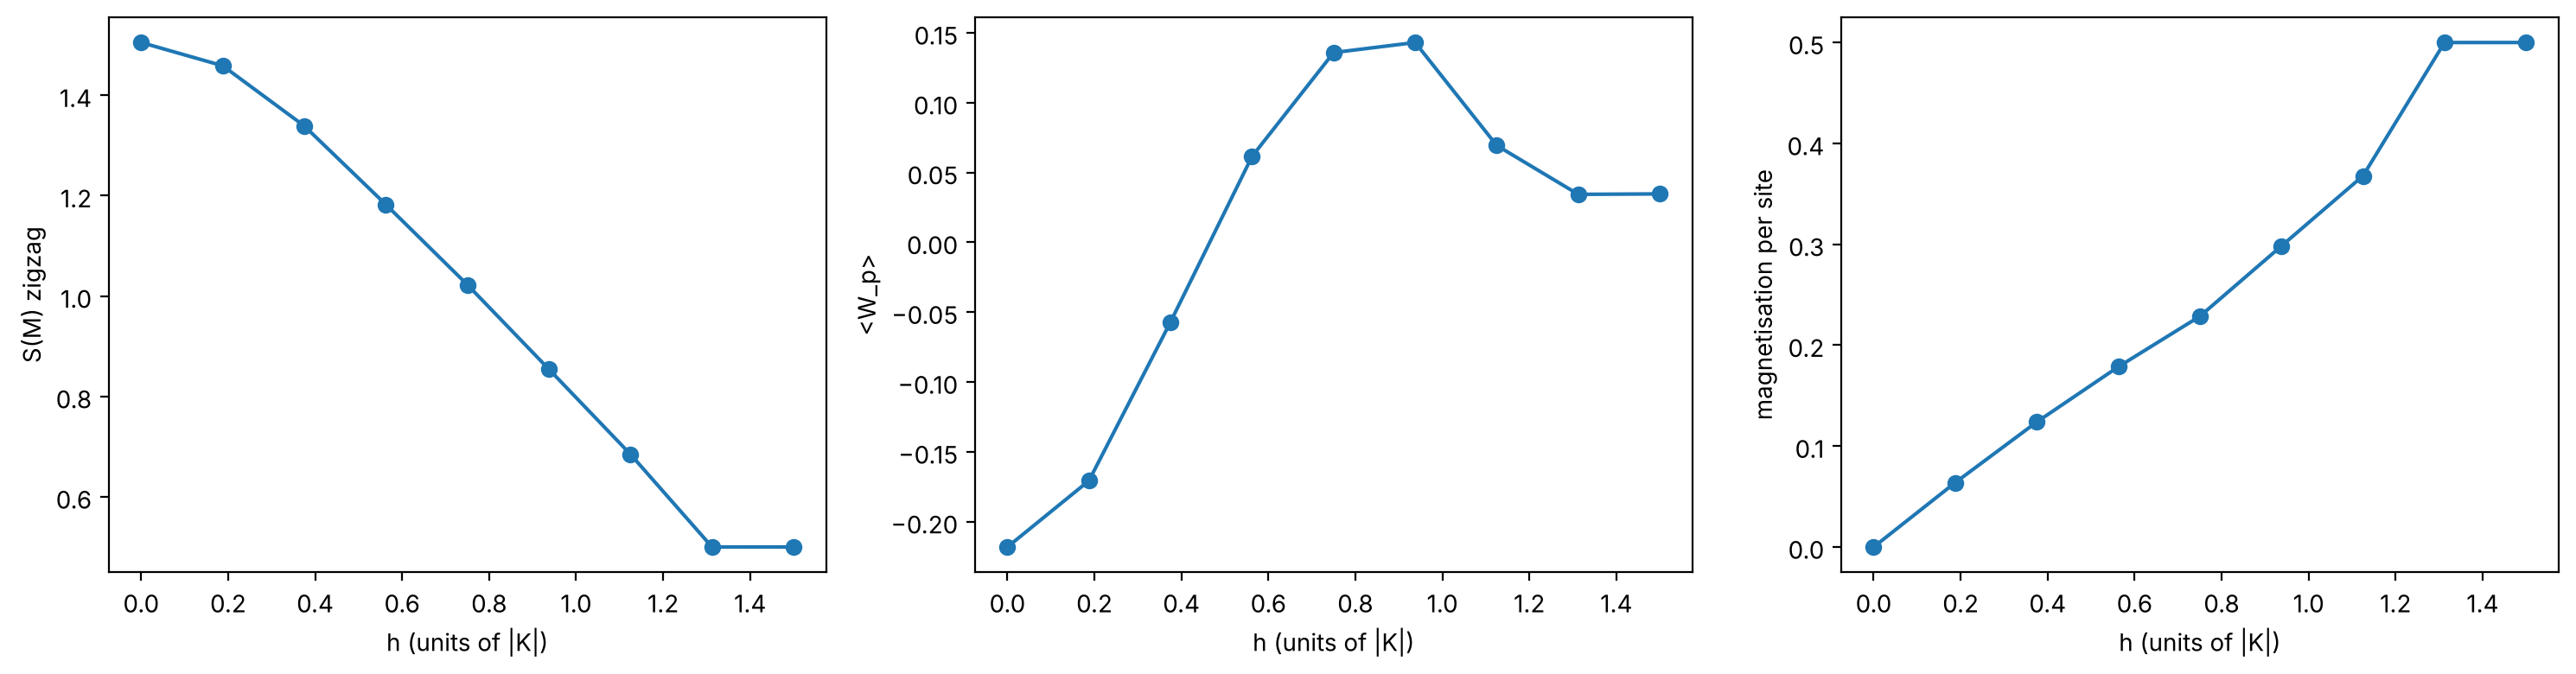

In [4]:
n111 = np.ones(3) / np.sqrt(3)
def field_point(h):
    ed = ED(models.kitaev_heisenberg_gamma(lat, **RuCl3, h=h * n111), lat.N)
    w, v = ed.diagonalize(k=2); psi = v[:, 0]
    C = ed.spin_correlations(psi)
    SM = ed.structure_factor(psi, lat.positions, P["M"], C=C)[0]
    W = np.real(np.mean([ed.expect(Wo, psi) for Wo in Wp]))
    m = np.real(sum(ed.expect(qslab.spin(i, a), psi) * n111[k] for i in range(lat.N) for k, a in enumerate("xyz"))) / lat.N
    return SM, W, m, w[1] - w[0]
hs = np.linspace(0, 1.5, 9)
t = time.time(); R = np.array(qslab.pmap(field_point, hs)); print(f"{time.time()-t:.1f}s")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hs, R[:, 0], "o-"); ax[0].set_ylabel("S(M) zigzag")
ax[1].plot(hs, R[:, 1], "o-"); ax[1].set_ylabel("<W_p>")
ax[2].plot(hs, R[:, 2], "o-"); ax[2].set_ylabel("magnetisation per site")
for a in ax: a.set_xlabel("h (units of |K|)")
plt.tight_layout(); plt.show()

## 3. DMRG on a honeycomb cylinder (complex MPO)

In [5]:
lat = lattice.honeycomb(3, 2, bc="cylinder")
H = models.kitaev_heisenberg_gamma(lat, **{k: v for k, v in RuCl3.items() if k != "J3"})
E_ed = ED(H, lat.N).ground_state()[0]
d = DMRG(H, lat.N, chi_max=64); d.run(8, verbose=False)
print("DMRG:", d.energy, " ED:", E_ed, " MPO dtype:", d.dtype)
lat = lattice.honeycomb(6, 2, bc="cylinder")
d = DMRG(models.kitaev_heisenberg_gamma(lat, **{k: v for k, v in RuCl3.items() if k != "J3"}), lat.N, chi_max=96)
d.run(6, verbose=True)

DMRG: -4.194667022702922  ED: -4.194667022702964  MPO dtype: complex128


sweep  0  chi=  16  E=-8.5325110517  E/N=-0.35552129  trunc=0.0e+00  S_mid=0.4960


sweep  1  chi=  32  E=-8.5444694217  E/N=-0.35601956  trunc=5.1e-06  S_mid=0.6328


sweep  2  chi=  64  E=-8.5446057992  E/N=-0.35602524  trunc=2.4e-07  S_mid=0.6378


sweep  3  chi=  96  E=-8.5446084696  E/N=-0.35602535  trunc=1.4e-08  S_mid=0.6380


sweep  4  chi=  96  E=-8.5446084694  E/N=-0.35602535  trunc=1.4e-08  S_mid=0.6380


-8.544608469444052

## 4. From first principles to model parameters
1. Run DFT+SOC on the material and Wannierise the $t_{2g}$ (or $j_\mathrm{eff}$) manifold.
2. Get the bilinear exchange matrices $\mathcal J_{ij}$, either from superexchange perturbation theory or from a magnetic-exchange code (for example a TB2J-type Green's-function method).
3. Express them in the cubic frame and read off $J, K, \Gamma, \Gamma'$ per bond type, or pass the full 3×3 matrix to `qslab.exchange(i, j, Jmat)`.
4. Run ED and DMRG with those couplings, compare S(q, ω) with INS and C(T) with heat-capacity data.

```python
H = qslab.Operator()
for b in lat.bonds(1):
    H = H + qslab.exchange(b.i, b.j, J_matrix_from_wannier[b.kind])   # 3x3 per bond type
```

## Quiz

In [6]:
from qslab import quiz
quiz.show("kitaev_heisenberg_gamma")

=== Generalised Kitaev materials (J-K-Gamma-Gamma') ===
alpha-RuCl3, Na2IrO3, Co-based honeycombs.

Q1. [mcq] What microscopic mechanism produces bond-dependent Kitaev exchange?
    (a) Weak SOC
    (b) Direct exchange only
    (c) Strong spin-orbit coupling, j_eff = 1/2, edge-sharing octahedra with 90-degree M-X-M bonds
    (d) Dipolar coupling

Q2. [mcq] Sign of K in alpha-RuCl3 (spin units, H = K S S)?
    (a) zero
    (b) ferromagnetic, K < 0
    (c) antiferromagnetic, K > 0
    (d) it depends on the field direction

Q3. [numeric] ED energy per site of the 12-site cluster with (J, K, Gamma, Gamma', J3) = (-0.1, -1, 0.5, -0.025, 0.1)?
    -> numeric answer (tolerance 2e-05)

Q4. [mcq] What does the zero-field ground state of alpha-RuCl3 show?
    (a) a spin liquid
    (b) Neel order
    (c) zigzag order (T_N ~ 7 K)
    (d) ferromagnetism

Q5. [mcq] Which DMRG requirement does the Gamma term change?
    (a) it makes the MPO complex because of the S^x S^y terms
    (b) it breaks the M